# Retail forecasting results exploration
Executed saved-output exploration. Models run in separate scripts. Hourly and daily scores are different tasks. Payroll dates are calendar proxies, not observed customer paydays.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
ext=root/'outputs/extensions'
metrics=pd.read_csv(ext/'metrics/daily_metrics.csv')
display(metrics.query("group=='all'"))

,model,scope,group,start,end,n,MAE,RMSE,MAPE_positive_only,MAPE_n,bias
0,Prophet_Without_Payday,common_and_full,all,2026-04-01,2026-07-14,105,185.173936,238.652217,19.737663,105,16.292521
3,Prophet_With_Payday,common_and_full,all,2026-04-01,2026-07-14,105,184.163368,237.649655,19.811835,105,24.403584
6,XGBoost_Without_Payday,common_and_full,all,2026-04-01,2026-07-14,105,324.707238,435.542029,25.799461,105,-275.828829
9,XGBoost_With_Payday,common_and_full,all,2026-04-01,2026-07-14,105,325.701409,437.261995,25.646603,105,-283.220252
12,LSTM_Without_Payday,common_and_full,all,2026-04-01,2026-07-14,105,264.470170,350.556652,22.607438,105,-169.037844
15,LSTM_With_Payday,common_and_full,all,2026-04-01,2026-07-14,105,263.162086,350.361040,22.379682,105,-169.685723
18,Hybrid_Without_Payday,common_and_full,all,2026-04-01,2026-07-14,105,237.738171,311.217953,21.107608,105,-127.766185
21,Hybrid_With_Payday,common_and_full,all,2026-04-01,2026-07-14,105,234.935098,309.118343,20.799157,105,-126.613002
24,Sequential_Hybrid_Without_Payday,common_and_full,all,2026-04-01,2026-07-14,105,280.710763,344.966612,31.875637,105,212.419917
27,Sequential_Hybrid_With_Payday,common_and_full,all,2026-04-01,2026-07-14,105,265.494492,328.060079,29.907278,105,206.393133


In [2]:
display(pd.read_csv(ext/'metrics/payday_effects.csv'))
display(pd.read_csv(ext/'metrics/block_bootstrap.csv'))

,family,group,n,MAE_change,RMSE_change,MAE_percent,RMSE_percent
0,Prophet,all,105,-1.010568,-1.002562,-0.545740,-0.420093
1,Prophet,payday,21,0.844243,0.724314,0.612262,0.388580
2,Prophet,non_payday,84,-1.474270,-1.332554,-0.748379,-0.532990
3,XGBoost,all,105,0.994171,1.719966,0.306175,0.394902
4,XGBoost,payday,21,0.649318,0.081617,0.210683,0.020501
5,XGBoost,non_payday,84,1.080384,2.088046,0.328549,0.469850
6,LSTM,all,105,-1.308084,-0.195612,-0.494606,-0.055800
7,LSTM,payday,21,-8.790463,-11.753296,-3.893636,-3.952755
8,LSTM,non_payday,84,0.562510,2.119141,0.205186,0.584362
9,Hybrid,all,105,-2.803073,-2.099610,-1.179059,-0.674643


,family,loss,block_days,n,mean_with_minus_without,ci_2_5,ci_97_5,assumption
0,Prophet,absolute,7,105,-1.010568,-3.023547,1.007621,circular blocks assume approximately stable de...
1,Prophet,absolute,14,105,-1.010568,-3.469629,1.300053,circular blocks assume approximately stable de...
2,Prophet,squared,7,105,-477.522309,-1370.683819,314.637486,circular blocks assume approximately stable de...
3,Prophet,squared,14,105,-477.522309,-1584.262604,385.454817,circular blocks assume approximately stable de...
4,XGBoost,absolute,7,105,0.994171,-3.460705,5.421982,circular blocks assume approximately stable de...
5,XGBoost,absolute,14,105,0.994171,-4.096554,5.272709,circular blocks assume approximately stable de...
6,XGBoost,squared,7,105,1501.192862,-2204.998673,4935.951316,circular blocks assume approximately stable de...
7,XGBoost,squared,14,105,1501.192862,-2543.561423,5213.836022,circular blocks assume approximately stable de...
8,LSTM,absolute,7,105,-1.308084,-6.476209,3.589359,circular blocks assume approximately stable de...
9,LSTM,absolute,14,105,-1.308084,-6.134054,3.541767,circular blocks assume approximately stable de...


In [3]:
display(pd.read_csv(ext/'metrics/expanding_validation.csv'))
display(pd.read_csv(ext/'metrics/planning_scenarios.csv'))

,family,payday,train_end,validation_start,validation_end_exclusive,n,MAE,RMSE,MAPE_positive_only,MAPE_n,bias
0,XGBoost,False,2025-09-30,2025-10-01,2026-01-01,92,119.305733,144.598272,17.034819,92,29.978204
1,XGBoost,True,2025-09-30,2025-10-01,2026-01-01,92,116.909857,141.947227,16.674504,92,26.762113
2,XGBoost,False,2025-12-31,2026-01-01,2026-02-01,31,156.028920,207.889205,18.355434,31,-103.251095
3,XGBoost,True,2025-12-31,2026-01-01,2026-02-01,31,151.691558,201.709333,18.062889,31,-91.543002
4,XGBoost,False,2026-01-31,2026-02-01,2026-03-01,28,125.886035,146.521842,15.965836,28,9.419919
5,XGBoost,True,2026-01-31,2026-02-01,2026-03-01,28,129.778025,151.819956,16.579658,28,18.696199
6,XGBoost,False,2026-02-28,2026-03-01,2026-04-01,31,205.353888,254.399647,44.961430,31,124.052202
7,XGBoost,True,2026-02-28,2026-03-01,2026-04-01,31,202.797072,252.681221,44.554927,31,125.153345


,model,training_threshold_GBP,peak_precision,peak_recall,underforecast_GBP,overforecast_GBP,scope
0,Prophet_Without_Payday,867.49,0.726316,0.958333,8866.274268,10576.988983,"illustrative revenue workload proxy, not staff..."
1,Prophet_With_Payday,867.49,0.729167,0.972222,8387.388676,10949.764973,"illustrative revenue workload proxy, not staff..."
2,XGBoost_Without_Payday,867.49,0.848485,0.388889,31528.143550,2566.116472,"illustrative revenue workload proxy, not staff..."
3,XGBoost_With_Payday,867.49,0.933333,0.388889,31968.387231,2230.260728,"illustrative revenue workload proxy, not staff..."
4,LSTM_Without_Payday,867.49,0.813333,0.847222,22759.170774,5010.197102,"illustrative revenue workload proxy, not staff..."
5,LSTM_With_Payday,867.49,0.830986,0.819444,22724.509980,4907.509026,"illustrative revenue workload proxy, not staff..."
6,Hybrid_Without_Payday,867.49,0.784810,0.861111,19188.978687,5773.529261,"illustrative revenue workload proxy, not staff..."
7,Hybrid_With_Payday,867.49,0.765432,0.861111,18981.275250,5686.910064,"illustrative revenue workload proxy, not staff..."
8,Sequential_Hybrid_Without_Payday,867.49,0.686869,0.944444,3585.269410,25889.360685,"illustrative revenue workload proxy, not staff..."
9,Sequential_Hybrid_With_Payday,867.49,0.690000,0.958333,3102.821340,24774.100339,"illustrative revenue workload proxy, not staff..."


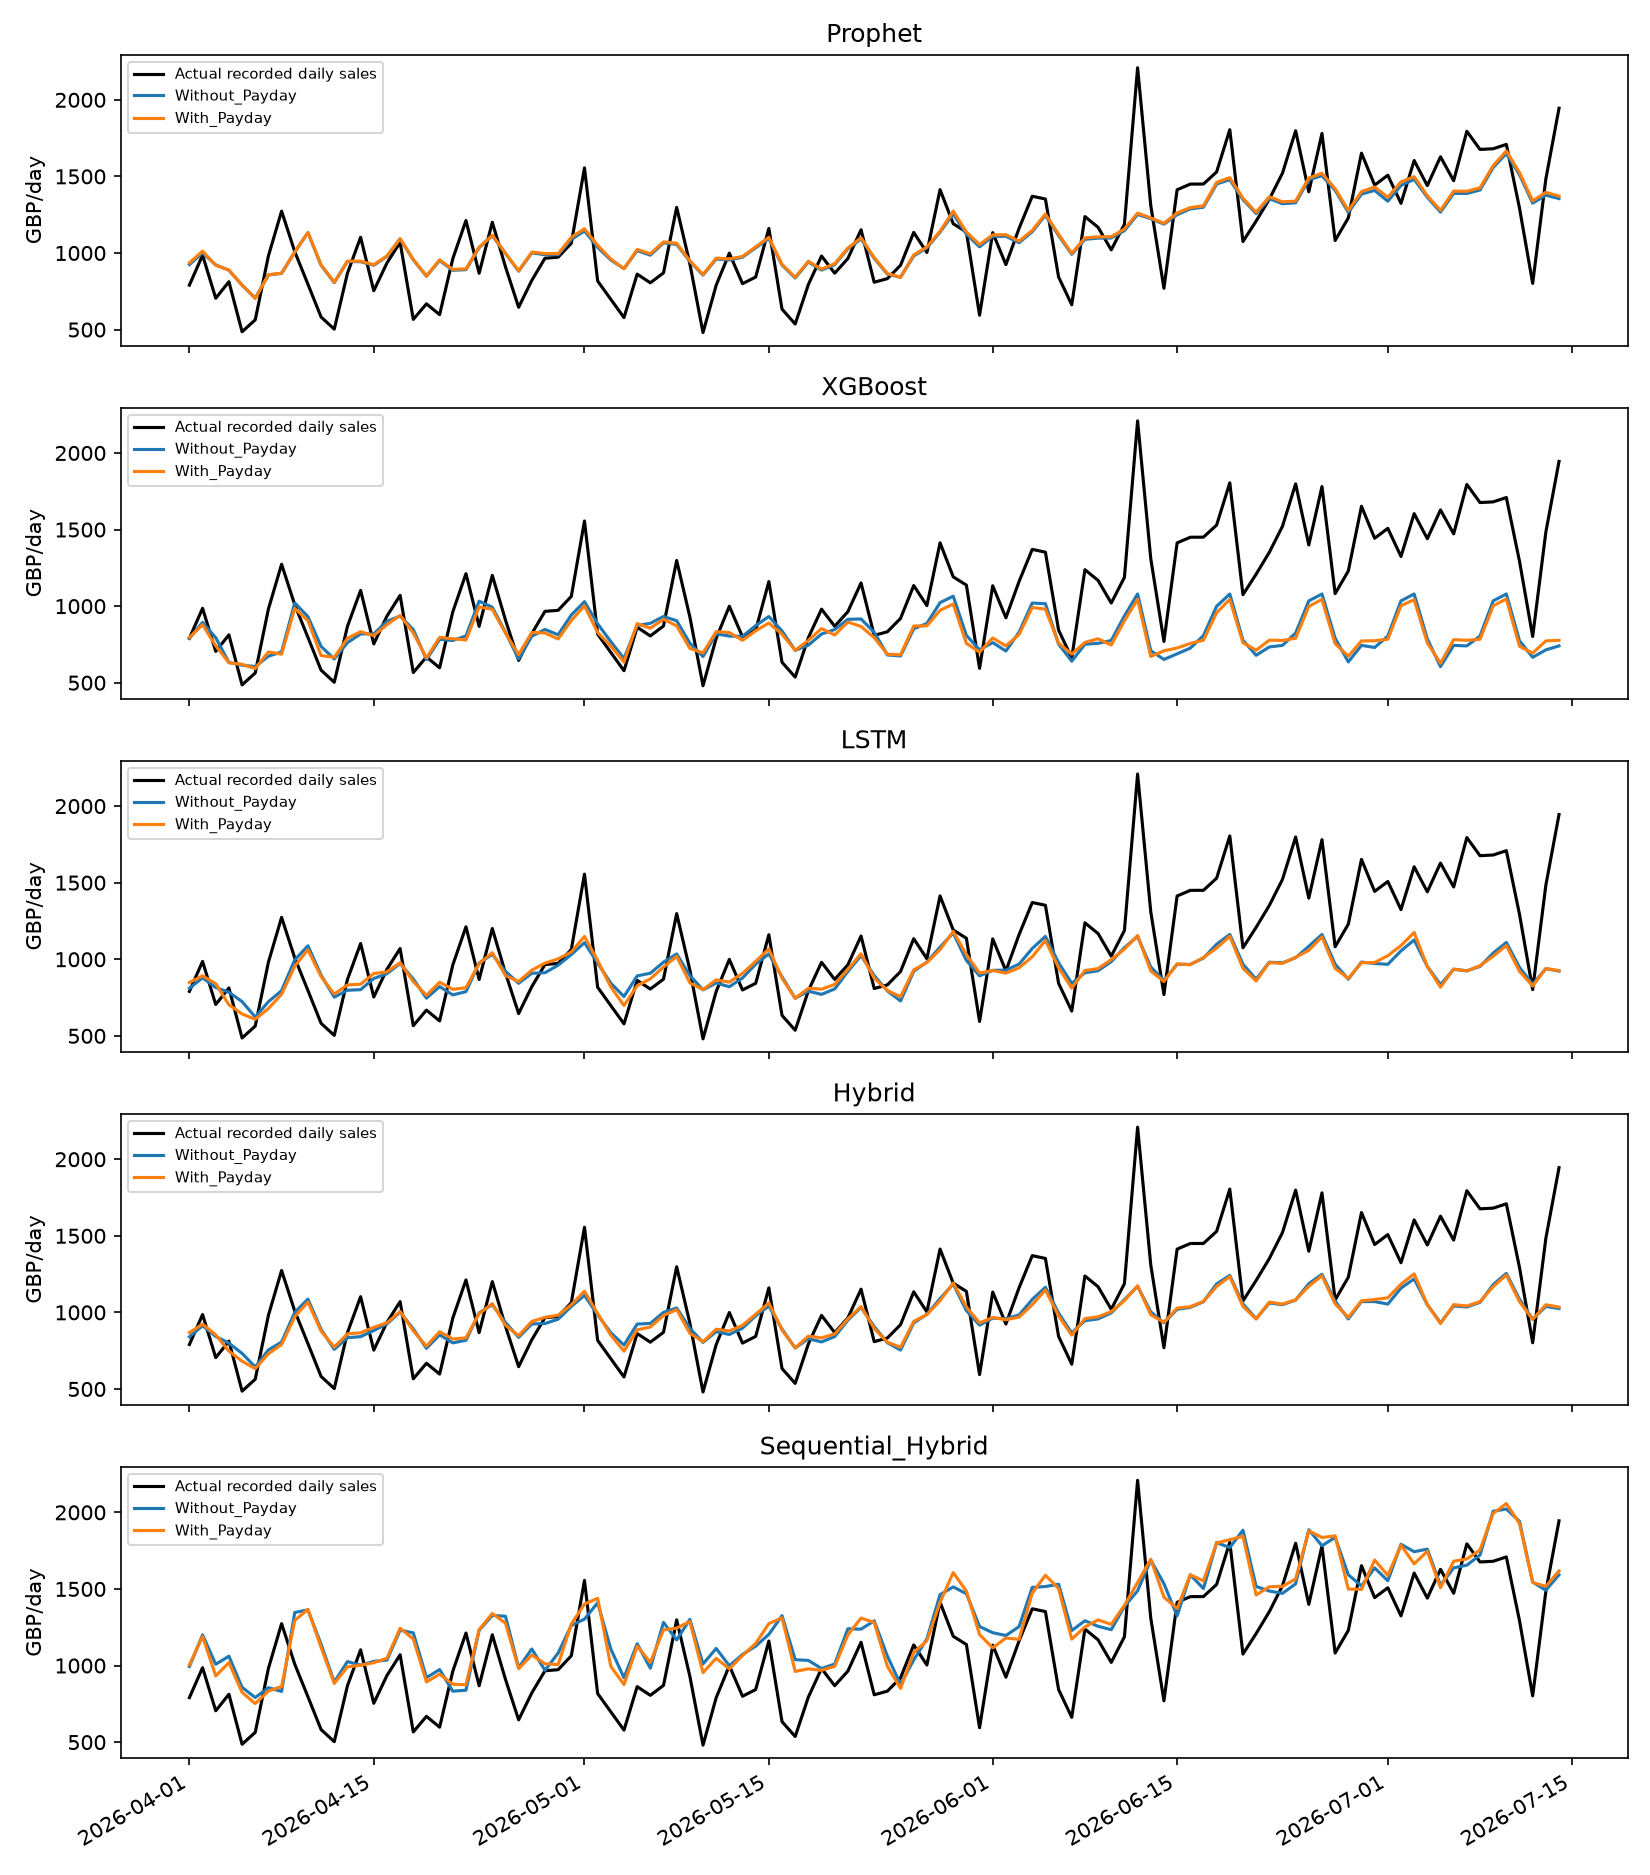

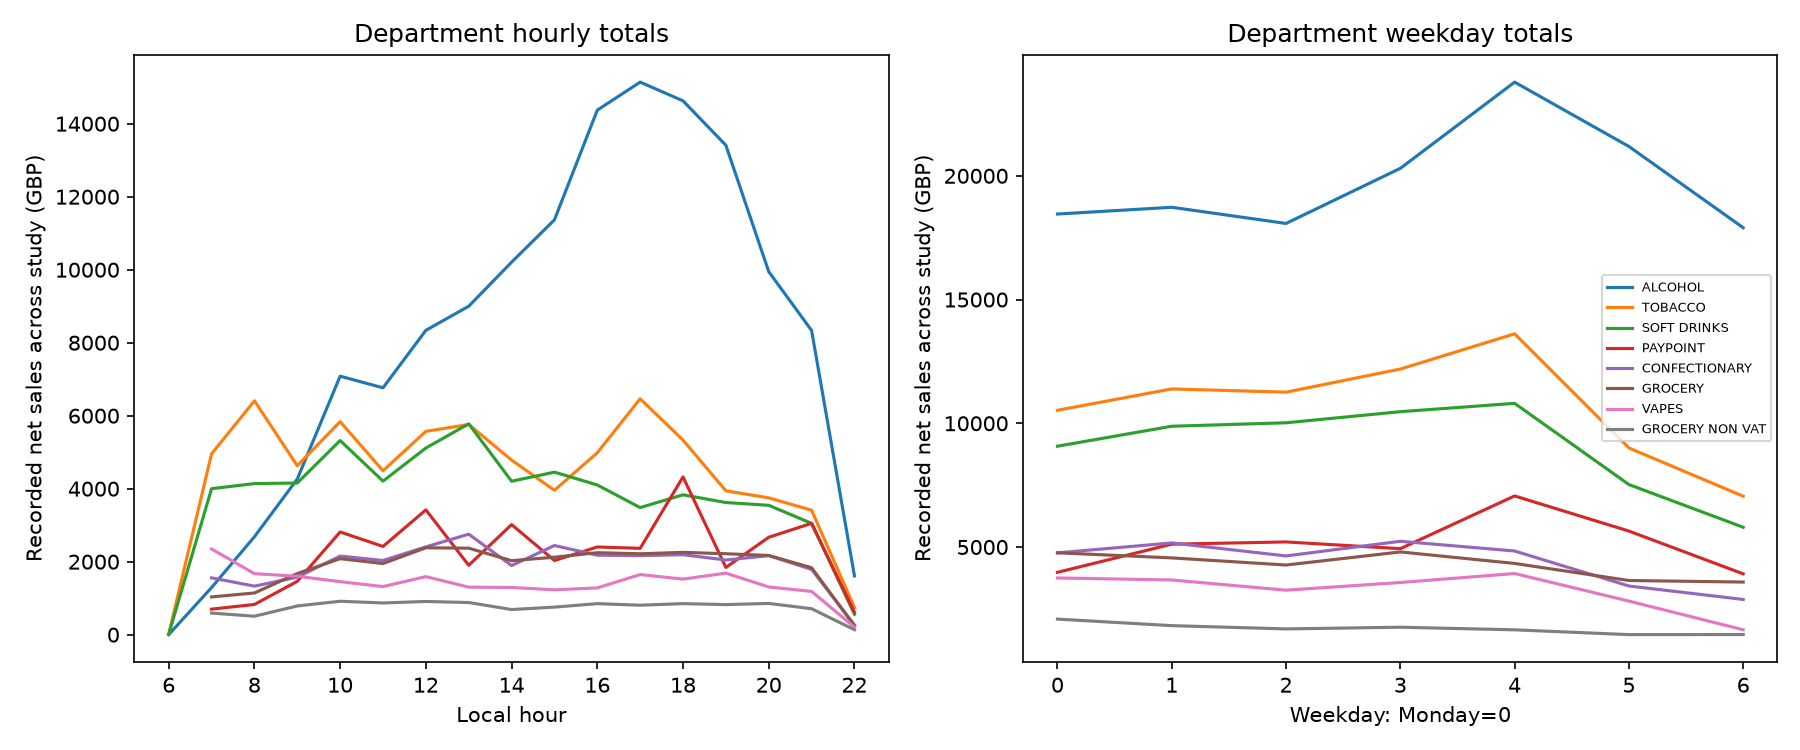

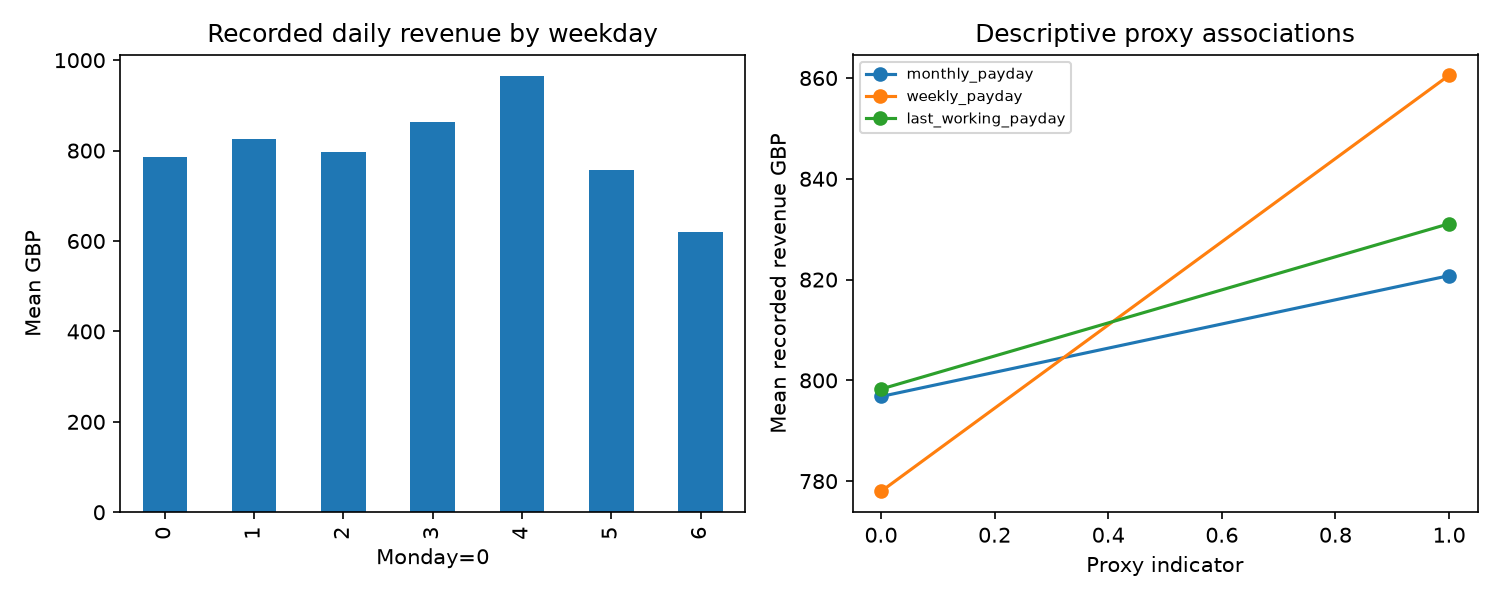

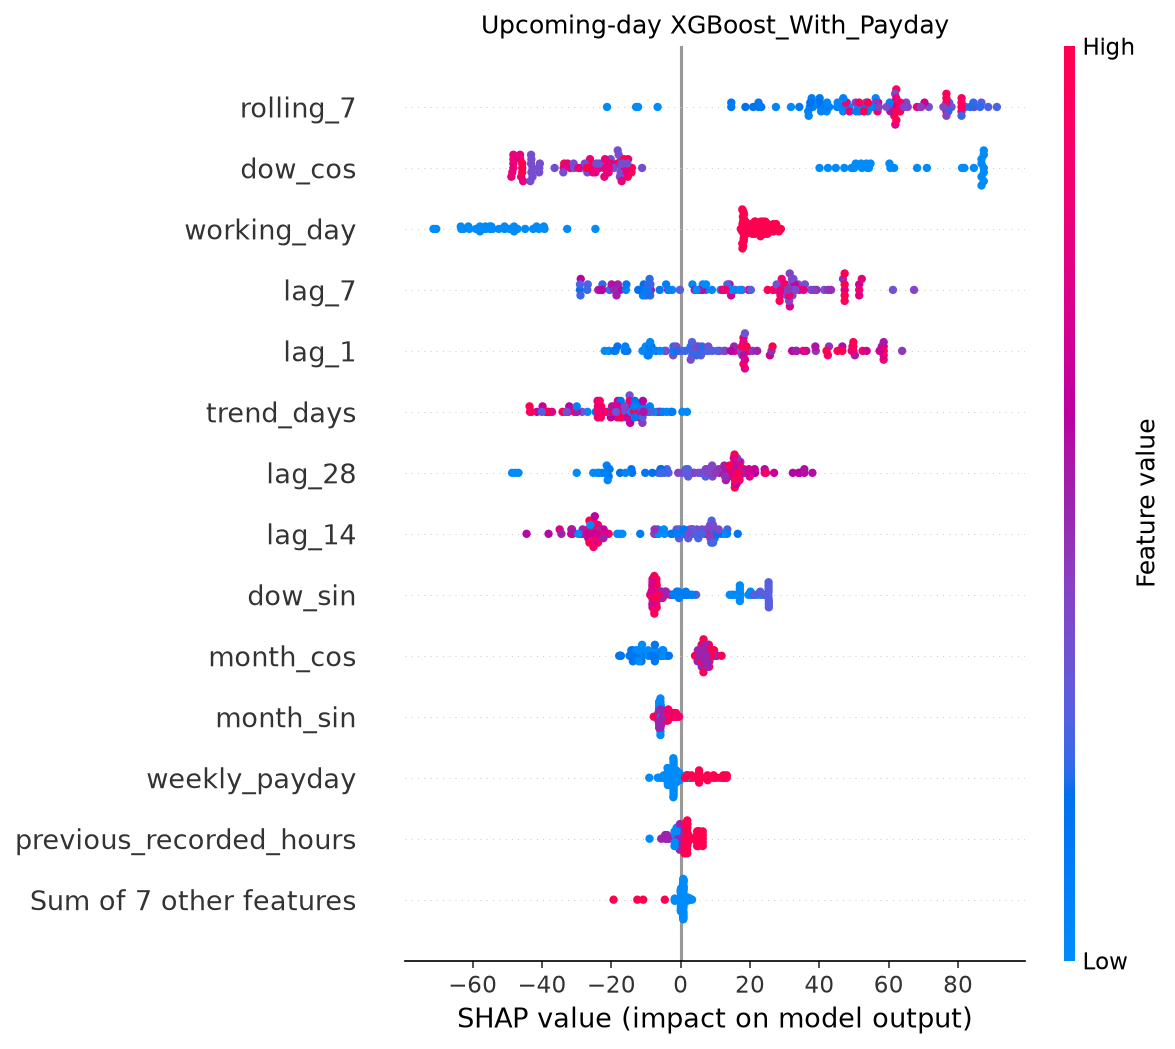

In [4]:
for filename in ['daily_actual_predictions.png','department_patterns.png','weekday_payday_eda.png','XGBoost_With_Payday_shap.png']:
    display(Image(filename=str(ext/'charts'/filename)))

Unknown within-day capture limits daily totals. Department associations and SHAP are noncausal. Planning metrics are illustrative workload/revenue proxies, not measured staffing or inventory benefits. Read reports/research_extensions.md for assumptions and remaining evidence.